# Highveld CO₂ — guided walkthrough

This notebook walks through the whole pipeline **one stage at a time**, in the order the code was built. Each
section says *what* we do, *why*, and then runs the real project code so you can see every intermediate result.

**How to use it:** run the cells top to bottom. After each section, change a number and re-run to see what
happens. When you can predict the output before running a cell, you understand that stage.

> **Which data am I looking at?** The first code cell checks `data/raw/oco2/` for real OCO-2 files. If there are none it
> generates **synthetic** files (clearly labelled) so you can learn the method first. **Synthetic output is a
> software test, not a scientific result.** The executed copy shipped with the project used synthetic data.

## 0. Setup

In [1]:
import sys, dataclasses
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))          # repo root, so `import highveld_co2` works

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from highveld_co2.config import RAW_DIR, SYNTH_DIR, BBOX, DEFAULT_PARAMS
from highveld_co2.synthetic import make_files

pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df"})

real = sorted(RAW_DIR.glob("*.nc*"))
if real:
    DATA_DIR, files = RAW_DIR, real
else:
    DATA_DIR = SYNTH_DIR
    if not list(SYNTH_DIR.glob("*.nc4")):
        make_files(SYNTH_DIR, n_days=730)
    files = sorted(SYNTH_DIR.glob("*.nc4"))
SYNTHETIC = DATA_DIR == SYNTH_DIR
print(("*** SYNTHETIC DATA (software test, not observations) ***" if SYNTHETIC else "REAL OCO-2 data"))
print(f"{len(files)} files in {DATA_DIR}")

*** SYNTHETIC DATA (software test, not observations) ***
137 files in C:\Users\SOOQ ELASER\OneDrive\Desktop\RemoteSensing\highveld-co2\data\raw\synthetic


## 1. The question and the study region

**Question:** can a satellite that measures *column* CO₂ see enhancements downwind of South Africa's coal power stations?

The Highveld in Mpumalanga hosts a dense cluster of large coal-fired power stations. We load the **real** plant
locations (from the WRI Global Power Plant Database, built by `scripts/build_reference.py`) and group plants that are
less than 30 km apart into **complexes**, because a satellite with a ~10 km swath cannot tell them apart.

In [2]:
from highveld_co2.sources import load_sources, group_complexes, SourceIndex

sources, complexes = group_complexes(load_sources(), eps_km=DEFAULT_PARAMS.complex_eps_km)
index = SourceIndex(sources)
display(sources[["source_id", "name", "fuel", "capacity_mw", "complex_id", "geolocation_source"]])
display(complexes[["complex_id", "name", "n_sources", "total_capacity_mw"]])

,source_id,name,fuel,capacity_mw,complex_id,geolocation_source
0,0,Kendal power station,Coal,4116.0,0,WRI
1,1,Majuba power station,Coal,4110.0,2,WRI
2,2,Lethabo power station,Coal,3708.0,3,WRI
3,3,Tutuka power station,Coal,3654.0,4,WRI
4,4,Matla power station,Coal,3600.0,0,WRI
5,5,Duvha power station,Coal,3600.0,1,WRI
6,6,Kriel power station,Coal,3000.0,0,WRI
7,7,Arnot power station,Coal,2352.0,1,WRI
8,8,Hendrina power station,Coal,2000.0,1,WRI
9,9,Camden power station,Coal,1600.0,5,WRI


,complex_id,name,n_sources,total_capacity_mw
0,0,Kendal power station complex,5,11510.0
1,1,Duvha power station complex,4,8952.0
2,2,Majuba power station,1,4110.0
3,3,Lethabo power station,1,3708.0
4,4,Tutuka power station,1,3654.0
5,5,Camden power station,1,1600.0
6,6,Grootvlei power station,1,1190.0
7,7,Kelvin power station,1,600.0
8,8,Rooiwal power station complex,2,480.0


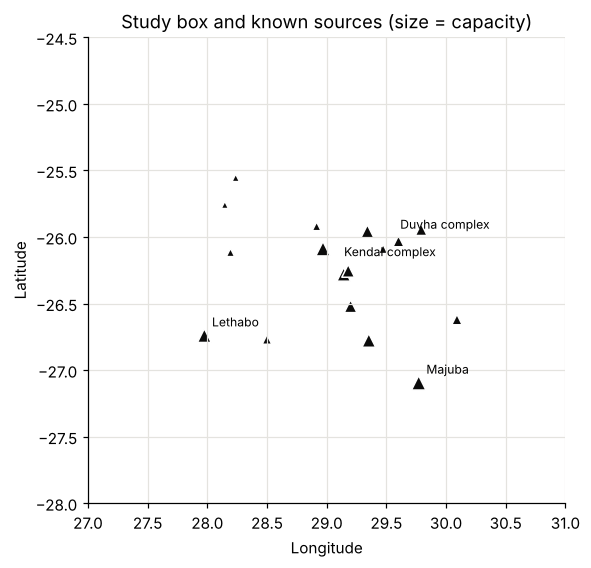

In [3]:
w, s, e, n = BBOX
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(sources.longitude, sources.latitude, s=20 + sources.capacity_mw.fillna(3000) / 60,
           c="#0b0b0b", marker="^", edgecolors="white")
for _, c in complexes.head(4).iterrows():
    ax.annotate(c["name"].replace(" power station", ""), (c.longitude, c.latitude), xytext=(5, 6), textcoords="offset points", fontsize=8)
ax.set_xlim(w, e); ax.set_ylim(s, n); ax.set_aspect(1 / np.cos(np.radians((s + n) / 2)))
ax.set_title("Study box and known sources (size = capacity)"); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.show()

**Things to notice:** the tight knot of plants around 29°E, 26°S is the Mpumalanga cluster; Lethabo and Grootvlei sit to
the west; Majuba to the south-east. *Exercise:* change `eps_km` to 10 and to 60 and watch `complexes` change. Why does a
coarser instrument force coarser attribution?

## 2. What an OCO-2 Lite file looks like

Real files are NetCDF4: self-describing containers with *groups* and *variables*. **Always inspect a new file before
writing code against it.** (`inspect_file` is the tool you will use first on real data.)

In [4]:
from highveld_co2.inspect_file import describe
describe(files[0], max_vars_per_group=12)

File: /home/claude/highveld-co2/data/raw/synthetic/oco2_LtCO2_210602_B11014Ar_synthetic.nc4
Global attributes: {'title': 'SYNTHETIC OCO-2-like Lite file for testing. NOT real observations.', 'synthetic': 'true'} ...

[/]  8 variables
  latitude                               float64   shape=(2344,)  degrees_north
  longitude                              float64   shape=(2344,)  degrees_east
  time                                   float64   shape=(2344,)  seconds since 1970-01-01 00:00:00 UTC
  xco2                                   float32   shape=(2344,)  ppm
  xco2_uncertainty                       float32   shape=(2344,)  ppm
  xco2_quality_flag                      int16     shape=(2344,)  
  sounding_id                            int64     shape=(2344,)  
  solar_zenith_angle                     float32   shape=(2344,)  degrees

[/Sounding]  2 variables
  operation_mode                         int8      shape=(2344,)  
  land_water_indicator                   int8      shape=(2344

The variables our code needs: `xco2`, `xco2_uncertainty`, `xco2_quality_flag`, `latitude`, `longitude`, `time`
(root) and `Sounding/operation_mode`, `Sounding/land_water_indicator`. If your real file names them differently, edit
`REQUIRED` / `OPTIONAL` in `highveld_co2/read_oco2.py` — that is the only place that knows about file layout.

## 3. Read one file — and meet the signal-to-background problem

`read_lite_file` returns the soundings inside our box as a table. Each row is one **sounding**: one retrieval of XCO₂
at one footprint.

1392 soundings in the box in this file


,xco2,xco2_unc,qf,lat,lon,t_s,sounding_id,op_mode,land_water,sza,time,file
0,414.014191,0.761521,0.0,-27.993838,28.143694,1.622633e+09,2021060211301901,0.0,0.0,40.0,2021-06-02 11:30:19.980000019+00:00,oco2_LtCO2_210602_B11014Ar_synthetic.nc4
1,414.702637,0.661471,0.0,-27.992095,28.156767,1.622633e+09,2021060211301902,0.0,0.0,40.0,2021-06-02 11:30:19.980000019+00:00,oco2_LtCO2_210602_B11014Ar_synthetic.nc4
2,414.513763,0.615821,0.0,-27.990352,28.169838,1.622633e+09,2021060211301903,0.0,0.0,40.0,2021-06-02 11:30:19.980000019+00:00,oco2_LtCO2_210602_B11014Ar_synthetic.nc4
3,415.413025,0.795339,0.0,-27.988607,28.182910,1.622633e+09,2021060211301904,0.0,0.0,40.0,2021-06-02 11:30:19.980000019+00:00,oco2_LtCO2_210602_B11014Ar_synthetic.nc4


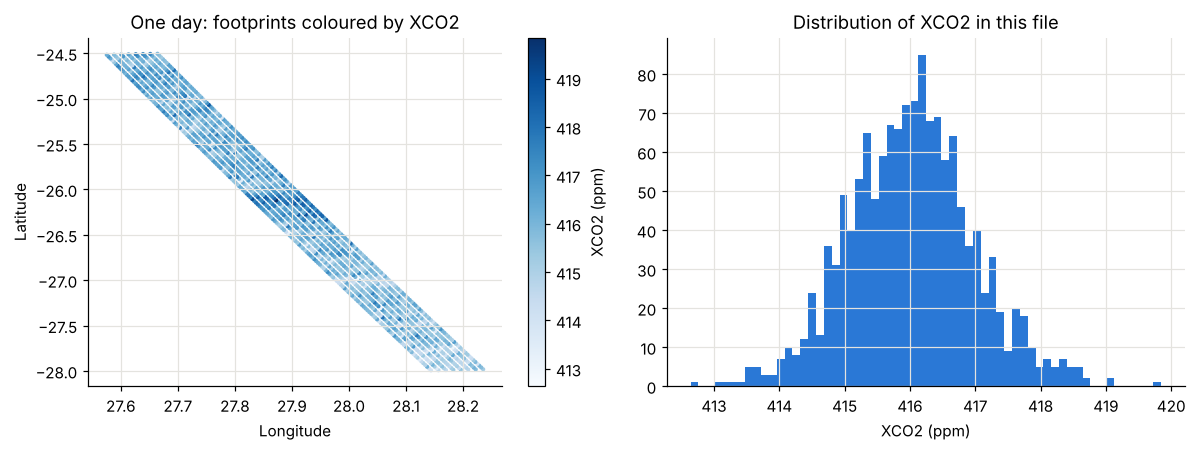

Spread of XCO2 across the whole file: 7.2 ppm. A power-plant plume adds only ~1-2 ppm on top of ~416 ppm.


In [5]:
from highveld_co2.read_oco2 import read_lite_file
one = read_lite_file(files[0])
print(len(one), "soundings in the box in this file")
display(one.head(4))

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2))
sc = a.scatter(one.lon, one.lat, c=one.xco2, s=3, cmap="Blues"); plt.colorbar(sc, ax=a, label="XCO2 (ppm)")
a.set_title("One day: footprints coloured by XCO2"); a.set_xlabel("Longitude"); a.set_ylabel("Latitude")
b.hist(one.xco2, bins=60, color="#2a78d6"); b.set_title("Distribution of XCO2 in this file"); b.set_xlabel("XCO2 (ppm)")
plt.tight_layout(); plt.show()
print(f"Spread of XCO2 across the whole file: {one.xco2.max() - one.xco2.min():.1f} ppm. "
      f"A power-plant plume adds only ~1-2 ppm on top of ~{one.xco2.median():.0f} ppm.")

**This is the central difficulty.** The signal we want (~1–2 ppm) is small compared with the day-to-day spread and with
the noise of single soundings. We cannot find plumes in raw XCO₂. We need to subtract a *background* — which is what the
next sections build.

Notice the geometry: the footprints form a thin strip — OCO-2 has a ~10 km wide swath.

## 4. Quality control

Not every sounding is trustworthy (clouds, aerosol, bad geometry). NASA provides `xco2_quality_flag` (0 = good). We also
keep land only, and nadir/glint modes only. `apply_qc` reports how many soundings each rule removed — **always look at
that report**; a rule that removes 90 % of the data is a red flag.

{'n_in': 169107, 'removed_quality_flag': 62223, 'removed_water': 0, 'removed_operation_mode': 0, 'n_out': 106884, 'fraction_kept': 0.632}


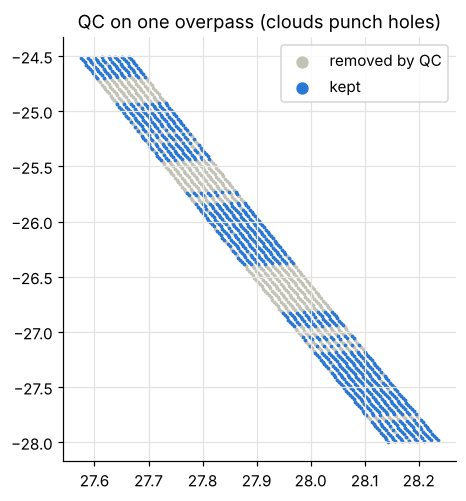

In [6]:
from highveld_co2.read_oco2 import read_many
from highveld_co2.qc import apply_qc

raw = read_many(files)
clean, qc_report = apply_qc(raw)
print(qc_report)

fig, ax = plt.subplots(figsize=(4.6, 5))
g = raw[raw.file == raw.file.iloc[0]]
ax.scatter(g.lon, g.lat, s=2, color="#c3c2b7", label="removed by QC")
ax.scatter(g[g.qf == 0].lon, g[g.qf == 0].lat, s=2, color="#2a78d6", label="kept")
ax.legend(markerscale=5); ax.set_title("QC on one overpass (clouds punch holes)"); plt.show()

## 5. Overpasses and the along-track coordinate

A daily file holds many orbits. We split soundings into **overpasses** wherever consecutive soundings are more than 5
minutes apart (a pass over our box takes ~1 minute; orbits are ~99 minutes apart). Then, for each pass, we project every
sounding onto the **first principal axis** of its coordinates — the strip's long direction — to get one number: *km
along the track*. That 1-D coordinate is what makes anomalies easy to plot and bin.

In [7]:
from highveld_co2.anomaly import compute_anomalies
soundings, passes = compute_anomalies(clean, index, DEFAULT_PARAMS)
print(f"{len(passes)} overpasses, {int(passes.is_valid.sum())} valid")
display(passes.head(6))
print("\nWhy are some passes invalid? Check the columns:")
display(passes[~passes.is_valid].head(4) if (~passes.is_valid).any() else "all passes valid in this data set")

137 overpasses, 135 valid


,pass_id,obs_date,t_start,n_good,n_far,extent_km,unc_median_ppm,background_ppm,sigma_ppm,is_valid
0,2021-06-02_0,2021-06-02,2021-06-02 11:30:19.980000019+00:00,865,580,389.250252,0.641887,415.721530,0.809391,True
1,2021-06-07_0,2021-06-07,2021-06-07 11:30:19.647000074+00:00,1179,531,393.752760,0.640514,415.142786,0.806815,True
2,2021-06-13_0,2021-06-13,2021-06-13 11:30:36.296999931+00:00,592,592,281.262600,0.646627,414.187378,0.759486,True
3,2021-06-18_0,2021-06-18,2021-06-18 11:30:19.980000019+00:00,1182,647,389.250809,0.649598,415.575412,0.852599,True
4,2021-06-23_0,2021-06-23,2021-06-23 11:30:20.312999964+00:00,1205,540,384.751167,0.652060,415.395794,0.825280,True
5,2021-06-29_0,2021-06-29,2021-06-29 11:30:42.957000017+00:00,460,460,236.252597,0.631915,414.885285,0.820500,True



Why are some passes invalid? Check the columns:


,pass_id,obs_date,t_start,n_good,n_far,extent_km,unc_median_ppm,background_ppm,sigma_ppm,is_valid
18,2021-09-06_0,2021-09-06,2021-09-06 11:30:38.960999966+00:00,232,40,261.007467,0.647732,NaN,NaN,False
65,2022-05-15_0,2022-05-15,2022-05-15 11:30:36.296999931+00:00,138,138,220.565239,0.661883,NaN,NaN,False


## 6. Background and anomaly — the heart of the method

For each pass, the **background** is what XCO₂ would have been without nearby sources. We estimate it from soundings more than
`exclude_km` (40 km) from *any* known source, as a **running median** along the track (a median ignores the odd plume that leaks
in; running means it follows slow trends). The **anomaly** is XCO₂ minus that background. The robust scatter
σ = 1.4826 × MAD tells us how noisy the pass is.

Below, one pass: grey points are far-field soundings used for the background; blue are soundings near a source.

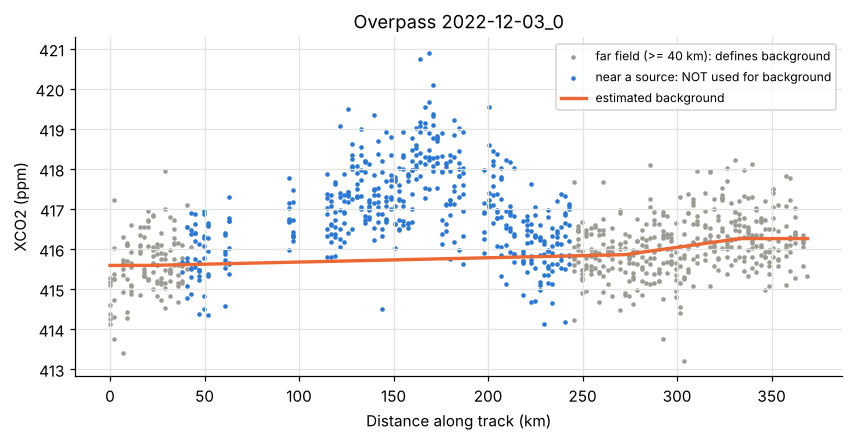

background 415.80 ppm | measured scatter sigma 0.64 ppm | reported uncertainty 0.66 ppm


In [8]:
best = soundings.groupby("pass_id").anomaly_ppm.max().idxmax()
g = soundings[soundings.pass_id == best].sort_values("s_km")
far = g.dist_src_km >= DEFAULT_PARAMS.exclude_km
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(g.s_km[far], g.xco2[far], s=4, color="#9c9b94", label=f"far field (>= {DEFAULT_PARAMS.exclude_km:g} km): defines background")
ax.scatter(g.s_km[~far], g.xco2[~far], s=4, color="#2a78d6", label="near a source: NOT used for background")
ax.plot(g.s_km, g.background_ppm, color="#eb6834", lw=2.2, label="estimated background")
ax.set_xlabel("Distance along track (km)"); ax.set_ylabel("XCO2 (ppm)"); ax.set_title(f"Overpass {best}"); ax.legend(fontsize=8)
plt.show()
p = passes[passes.pass_id == best].iloc[0]
print(f"background {p.background_ppm:.2f} ppm | measured scatter sigma {p.sigma_ppm:.2f} ppm | reported uncertainty {p.unc_median_ppm:.2f} ppm")

**Compare σ with the reported uncertainty.** On real data the measured scatter is usually *larger* than the reported
per-sounding uncertainty, because real errors are spatially correlated. Using the measured σ (not the reported one) is the
safer choice. *Exercise:* in `config.Params` switch `background_method` to `"median"` and re-run sections 5–6. What happens
on passes with a long-range gradient?

## 7. Bins and events

A single sounding is far too noisy to flag. Averaging the ~10–40 soundings inside a 5 km bin shrinks the noise by √n. A bin
is **flagged** only if its mean anomaly is both big in ppm (≥ 1) *and* big relative to its standard error (z ≥ 3). Adjacent
flagged bins in one pass merge into one **event**.

6,992 bins, 357 flagged -> 167 events


,pass_id,obs_date,n_bins,length_km,peak_anomaly_ppm,peak_z,nearest_source,dist_source_km,attributed
125,2022-12-03_0,2022-12-03,16,80.0,2.888101,17.887692,Secunda Synfuels (Sasol),25.679561,True
99,2022-09-14_0,2022-09-14,5,25.0,2.857512,15.522007,Komati Power Station,23.162300,True
15,2021-09-27_0,2021-09-27,4,20.0,2.671679,17.328395,Secunda Synfuels (Sasol),24.986789,True
120,2022-11-17_0,2022-11-17,7,35.0,2.657707,13.670431,Duvha power station,8.542966,True
98,2022-09-14_0,2022-09-14,5,25.0,2.613470,17.689277,Tutuka power station,13.983884,True
66,2022-05-04_0,2022-05-04,9,45.0,2.423363,10.786299,Kelvin power station,31.230712,True
79,2022-06-21_0,2022-06-21,17,85.0,2.374375,13.373567,Kelvin power station,39.579300,True
52,2022-03-17_0,2022-03-17,4,20.0,2.278324,8.503304,Kelvin power station,32.658683,True


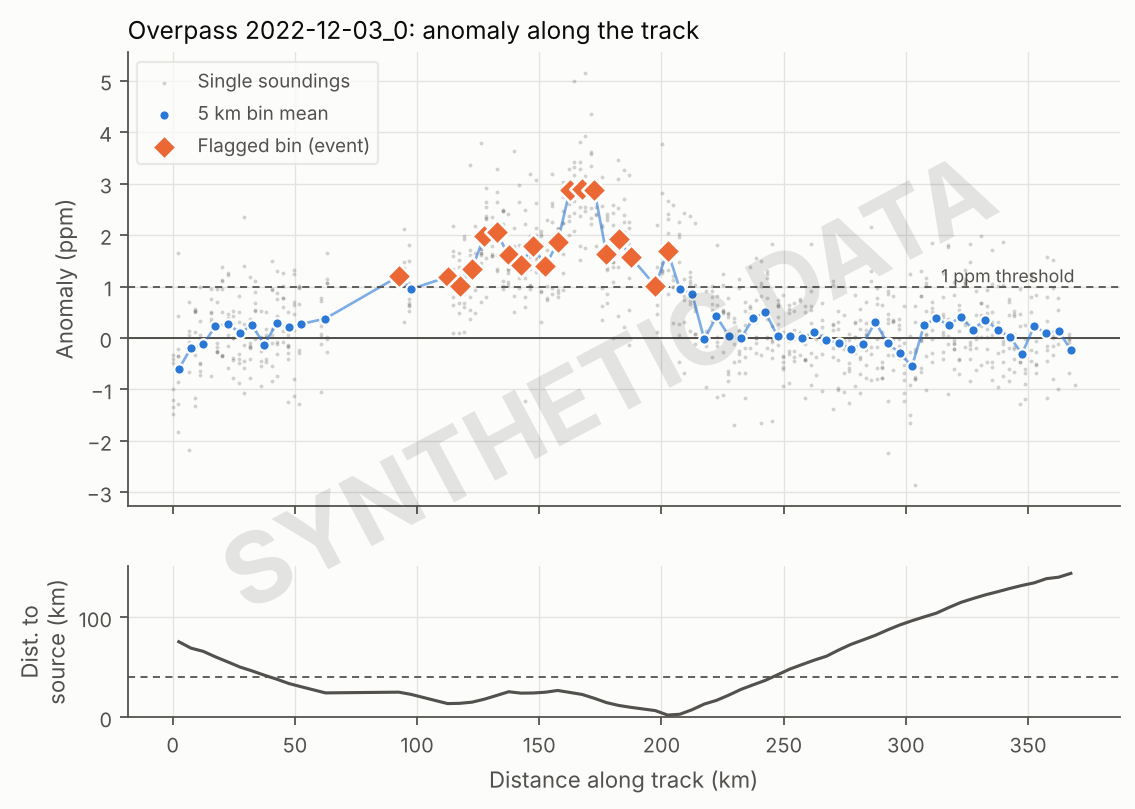

In [9]:
from highveld_co2.events import bin_passes, group_events
from highveld_co2.attribute import link_events, cluster_hotspots, complex_stats, control_test
from highveld_co2 import mapping

bins = bin_passes(soundings, index, DEFAULT_PARAMS)
events = link_events(group_events(bins, DEFAULT_PARAMS), index, DEFAULT_PARAMS)
print(f"{len(bins):,} bins, {int(bins.flagged.sum())} flagged -> {len(events)} events")
display(events.sort_values("peak_anomaly_ppm", ascending=False)[
    ["pass_id", "obs_date", "n_bins", "length_km", "peak_anomaly_ppm", "peak_z", "nearest_source", "dist_source_km", "attributed"]].head(8))

pid = events.sort_values("peak_anomaly_ppm", ascending=False).pass_id.iloc[0]
mapping.fig_example_pass(soundings, bins, pid, "/tmp/example_pass.png", DEFAULT_PARAMS, synthetic=SYNTHETIC)
display(Image("/tmp/example_pass.png"))

Read the bottom panel: the track passes close to a source exactly where the flagged diamonds are. That is the picture of a
detection. *Exercise:* raise `min_enh_ppm` to 1.5 and lower it to 0.6 (use `dataclasses.replace(DEFAULT_PARAMS, min_enh_ppm=...)`),
re-run, and count events. This trade-off between missed plumes and false alarms is the core tuning problem.

## 8. Attribution and hotspots

Each event is linked to its nearest source. It is "attributed" if within `attrib_km` (40 km — deliberately equal to the
background exclusion radius, see `config.py`). Events are then clustered into **hotspots** (events within 20 km). A hotspot with
many events on different days and *no* source nearby deserves attention: it is either an unlisted source or an artefact.

**Careful:** proximity is not proof. Johannesburg/Pretoria CO₂ sits near small power stations and can be mis-attributed to them.

In [10]:
hotspots = cluster_hotspots(events, DEFAULT_PARAMS)
display(hotspots.head(8).round(2))

,hotspot_id,n_events,n_distinct_days,lat,lon,mean_peak_ppm,median_dist_source_km,explained_by_source
0,1,72,30,-26.44,29.43,1.41,15.24,True
1,0,62,25,-26.35,27.92,1.38,32.23,True
2,2,12,11,-25.87,30.83,1.25,103.85,False
3,6,4,4,-25.07,27.71,1.17,74.27,False
4,5,3,3,-26.84,30.98,1.24,91.70,False
5,9,2,2,-27.87,28.17,1.11,125.91,False
6,8,2,2,-27.63,28.13,1.24,99.31,False
7,14,2,2,-24.51,29.09,1.04,144.13,False


## 9. How often is each source actually seen? (detection frequency)

A bare count of detections is misleading: a source seen on 3 passes and a source seen on 40 passes can have the same count.
Because we kept **all** soundings — not just detections — we can count the passes that *observed* each complex and report
`events ÷ observed passes` with a 95 % Wilson interval. This is the single most useful number in the project.

In [11]:
cstats = complex_stats(bins, sources, complexes, DEFAULT_PARAMS)
display(cstats.round(3))

,complex_id,name,n_sources,total_capacity_mw,observed_passes,event_passes,frequency,ci_low,ci_high
0,0,Kendal power station complex,5,11510.0,45,25,0.556,0.412,0.691
1,1,Duvha power station complex,4,8952.0,46,21,0.457,0.322,0.598
2,2,Majuba power station,1,4110.0,45,12,0.267,0.160,0.410
3,3,Lethabo power station,1,3708.0,44,12,0.273,0.163,0.418
4,4,Tutuka power station,1,3654.0,43,20,0.465,0.325,0.611
5,5,Camden power station,1,1600.0,0,0,NaN,NaN,NaN
6,6,Grootvlei power station,1,1190.0,0,0,NaN,NaN,NaN
7,7,Kelvin power station,1,600.0,40,22,0.550,0.398,0.693
8,8,Rooiwal power station complex,2,480.0,42,10,0.238,0.135,0.385


Look for complexes with `observed_passes = 0`: **no overpass ever sampled them**, so the pipeline says nothing about them —
which is itself an honest and important finding about the instrument's coverage.

## 10. The control test — are our detections real?

If the pipeline flags bins just as often **far** from any source as **near** one, it is detecting noise. The control test
compares the flagged rate near sources (≤ 40 km) with the rate far away (≥ 60 km; the gap is a buffer). The interval comes
from a bootstrap over **passes**, not bins, because bins in one pass share a background and are not independent.

{'near_bins': 2526, 'near_flagged': 312, 'far_bins': 3792, 'far_flagged': 44, 'near_rate': 0.1235, 'far_rate': 0.0116, 'rate_ratio': 10.6448, 'fisher_p': 0.0, 'rate_ratio_ci': (7.019562574484194, 16.59015911006184)}


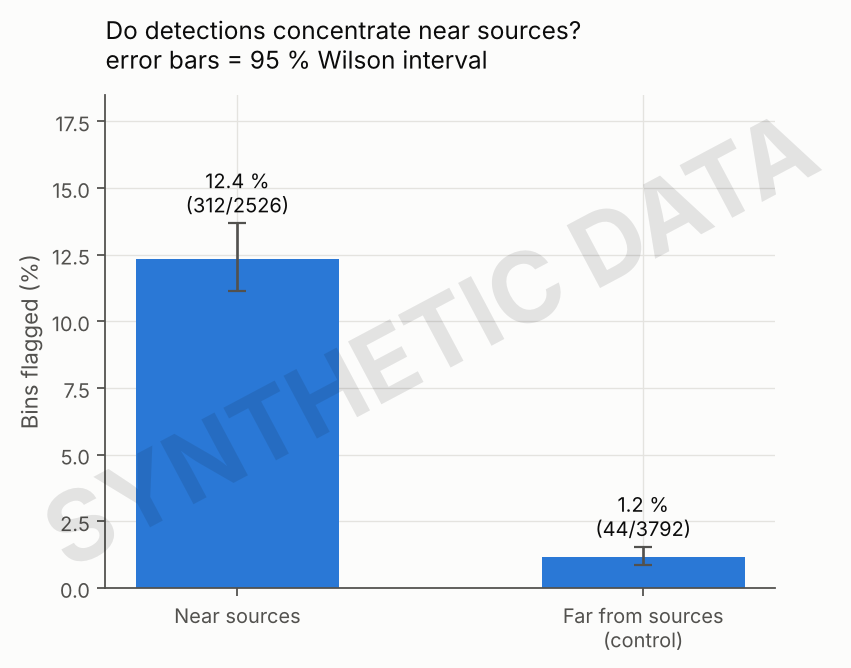

In [12]:
control = control_test(bins, DEFAULT_PARAMS)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in control.items()})
mapping.fig_control(control, "/tmp/control.png", synthetic=SYNTHETIC)
display(Image("/tmp/control.png"))

**Sensitivity analysis:** a result that depends on one arbitrary setting is fragile. Vary the exclusion radius and see whether the
near/far contrast survives. (`attrib_km` and `near_km` must move with `exclude_km`, as explained in `config.py`.)

In [13]:
from highveld_co2.anomaly import compute_anomalies as _ca
rows = []
for ex in (20, 30, 40, 60):
    P = dataclasses.replace(DEFAULT_PARAMS, exclude_km=ex, attrib_km=ex, near_km=ex, cover_radius_km=ex, far_km=max(60, ex + 20))
    snd, _ = _ca(clean, index, P)
    b = bin_passes(snd, index, P)
    c = control_test(b, P, n_boot=300)
    rows.append({"exclude_km": ex, "near_rate": c["near_rate"], "far_rate": c["far_rate"], "rate_ratio": c.get("rate_ratio"),
                 "ratio_ci": tuple(round(x, 1) for x in c.get("rate_ratio_ci", (np.nan, np.nan)))})
display(pd.DataFrame(rows).round(3))

,exclude_km,near_rate,far_rate,rate_ratio,ratio_ci
0,20,0.055,0.011,4.884,"(2.7, 8.3)"
1,30,0.099,0.012,8.385,"(5.0, 13.0)"
2,40,0.124,0.012,10.645,"(6.9, 15.8)"
3,60,0.132,0.011,12.355,"(8.3, 19.7)"


## 11. Compositing: from sparse passes to a map and a profile

One overpass shows little; averaging many can reveal a persistent source. We grid the bin anomalies (0.1° ≈ 10 km cells) and
compute the mean anomaly against distance from the nearest source with a bootstrap-over-passes interval.

,r_lo_km,r_hi_km,n_bins,n_passes,mean_anomaly_ppm,ci_low,ci_high
0,0.0,10.0,286,82,0.242,0.108,0.377
1,10.0,20.0,542,88,0.188,0.045,0.326
2,20.0,30.0,798,88,0.104,-0.021,0.226
3,30.0,40.0,900,88,0.232,0.118,0.349
4,40.0,60.0,674,89,0.028,-0.003,0.057
5,60.0,80.0,609,89,0.000,-0.044,0.044
6,80.0,100.0,1148,133,-0.001,-0.025,0.023


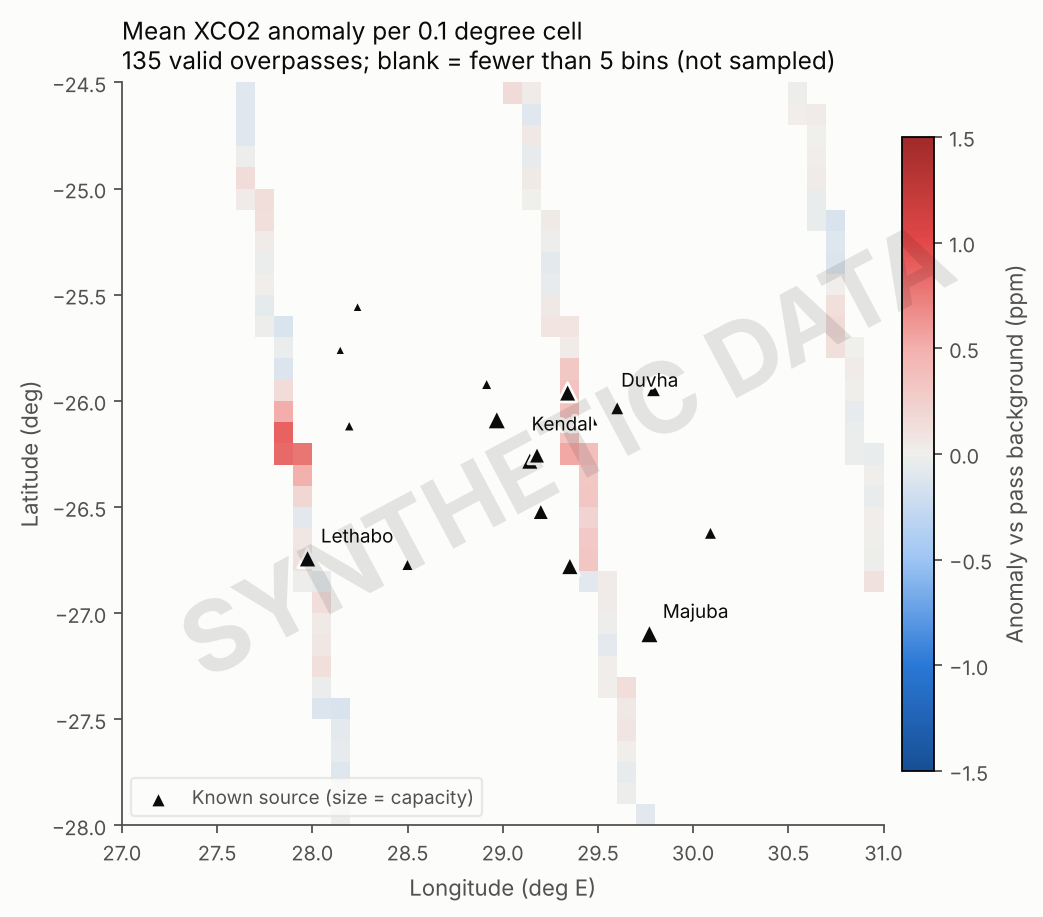

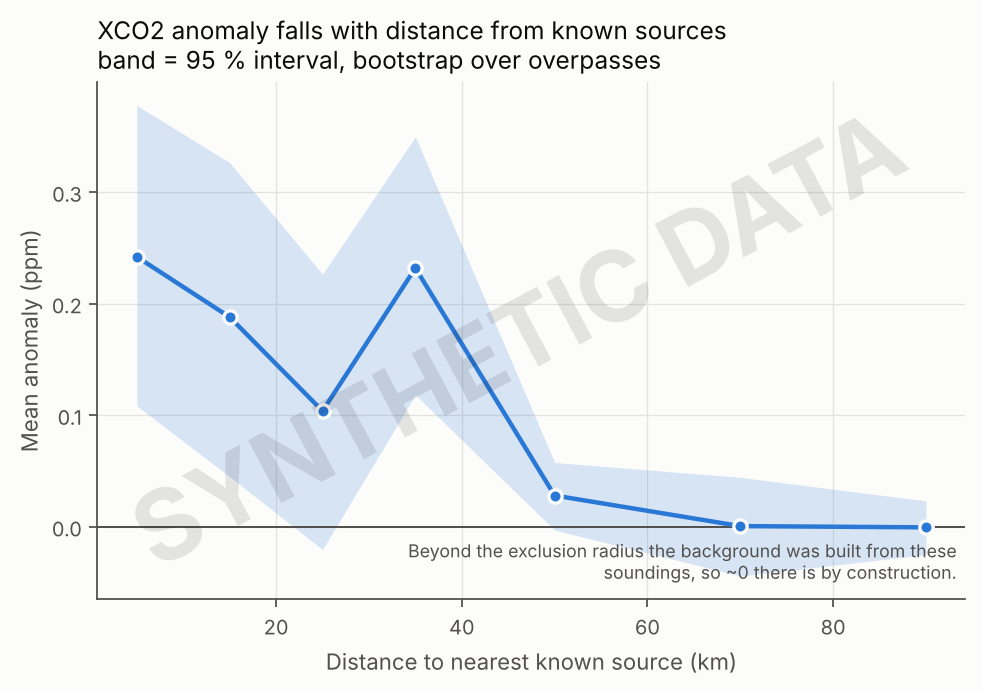

In [14]:
from highveld_co2.composite import grid_mean, radial_profile
grid = grid_mean(bins); profile = radial_profile(bins)
display(profile.round(3))
mapping.fig_anomaly_map(grid, sources, complexes, "/tmp/map.png", n_passes=int(passes.is_valid.sum()), synthetic=SYNTHETIC)
mapping.fig_radial_profile(profile, "/tmp/profile.png", synthetic=SYNTHETIC)
display(Image("/tmp/map.png")); display(Image("/tmp/profile.png"))

**Reading the map:** the stripes are the satellite's ground tracks — the blank space is *where OCO-2 never looked*. That is the
sampling limitation made visible. **Reading the profile:** beyond the exclusion radius the background was built from those same
soundings, so ~0 there is by construction; the information is in the inner rings.

## 12. Store results in PostGIS

Start the database first (`make db-up`, or point `DATABASE_URL` at your own PostGIS). `save_all` creates the schema, **replaces**
the table contents (so re-runs are safe) and loads every table. This cell is safe to skip.

In [15]:
try:
    from highveld_co2.db import get_engine, save_all, run_query
    eng = get_engine()
    with eng.connect():
        pass
    counts = save_all(sources, complexes, passes, bins, events, cstats, engine=eng)
    print("rows loaded:", counts)
    print("\n-- detection frequency per complex (SQL) --")
    display(run_query("complex_frequency", engine=eng))
    print("-- control test (SQL) - must match section 10 exactly --")
    display(run_query("control_test", engine=eng))
    top = complexes.set_index("complex_id").loc[cstats.sort_values("event_passes").complex_id.iloc[-1]]
    print(f"-- events within 40 km of {top['name']} (SQL ST_DWithin on geography) --")
    display(run_query("events_near_point", engine=eng, lon=float(top.longitude), lat=float(top.latitude), km=40).head(5))
except Exception as exc:
    print("PostGIS not reachable - skipping.  (", type(exc).__name__, ")")
    print("Start it with `make db-up`, then re-run this cell.")

rows loaded: {'source_complexes': 9, 'sources': 17, 'passes': 137, 'bins': 6992, 'events': 167, 'complex_stats': 9}

-- detection frequency per complex (SQL) --


,name,observed_passes,event_passes,frequency,ci_low,ci_high
0,Duvha power station complex,46,21,0.457,0.322,0.598
1,Kendal power station complex,45,25,0.556,0.412,0.691
2,Majuba power station,45,12,0.267,0.160,0.410
3,Lethabo power station,44,12,0.273,0.163,0.418
4,Tutuka power station,43,20,0.465,0.325,0.611
5,Rooiwal power station complex,42,10,0.238,0.135,0.385
6,Kelvin power station,40,22,0.550,0.398,0.693
7,Camden power station,0,0,NaN,NaN,NaN
8,Grootvlei power station,0,0,NaN,NaN,NaN


-- control test (SQL) - must match section 10 exactly --


,zone,bins,flagged,flag_rate
0,far,3792,44,0.0116
1,near,2526,312,0.1235


-- events within 40 km of Kendal power station complex (SQL ST_DWithin on geography) --


,event_id,obs_date,peak_ppm,km
0,113,2022-11-01,1.23,30.8
1,145,2023-02-05,1.17,30.8
2,132,2023-01-04,1.57,30.9
3,77,2022-06-10,1.22,30.9
4,28,2021-11-14,1.25,31.1


## 13. Exercises, and what to do with real data

1. **Wind.** Add wind (ERA5 or MERRA-2) and attribute events to the source *upwind* of them instead of the nearest one.
2. **Capacity plausibility.** An event near a 180 MW plant with a 3 ppm peak is implausible. Add a check against capacity.
3. **NO₂ tracer.** Coal plants co-emit NO₂, which Sentinel-5P sees at much higher contrast. Use it to confirm candidate CO₂ events.
4. **Seasonality.** Run `run_query("events_by_month")`. Is there a dry-season effect (fewer clouds, but biomass burning)?
5. **Robustness.** Repeat section 10 with `background_method="median"` and with `min_bin_n=3`.
6. **Your own question.** Pick a different region (another coal belt, a megacity) and change `BBOX` and the source list.

**With real data:** replace the synthetic files with real ones (README, "Run on real data"), re-run this notebook,
and treat every number sceptically: compare σ with the reported uncertainty (section 6), check the control test (section 10),
and look at the coverage (section 11) before you write a single sentence of conclusion.